# Tarea 2 · Parte 2 — De los modelos base a la extracción estructurada

Evaluamos los modelos de la Parte 1 contra **referencias manuales** y los comparamos con alternativas, siempre sobre
**los mismos 10 documentos y 10 clips** del corpus original. Luego extraemos campos estructurados con un LLM local y
auditamos a mano 20 extracciones.

Reglas que seguimos para no inflar métricas:

1. La muestra y todas las configuraciones se fijaron **antes** de calcular cualquier métrica (sección 1 y 2) y no se tocaron después.
2. Las referencias se escribieron a mano mirando la imagen o escuchando el audio, con una herramienta que **oculta** la
   salida de los modelos (`herramientas/anotar_referencias.py`).
3. Referencias y salidas se normalizan con el mismo criterio (`t2.normalizar`: minúsculas, sin puntuación, sin marcas
   `[HABLANTE_n]` ni `[?]`; se conservan tildes y ortografía antigua).

In [1]:
import os, sys, json, time, subprocess, warnings
from pathlib import Path
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import soundfile as sf
from IPython.display import display, Markdown, Image

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "herramientas"))
sys.path.insert(0, str(RAIZ.parent / "sessions" / "13-audio-a-texto"))
import t2, voz, preparar_muestra

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 80)
DATOS = RAIZ / "datos"
documentos = pd.read_csv(DATOS / "documentos.csv")
transcripciones = pd.read_csv(DATOS / "transcripciones.csv")
print(f"Corpus de la Parte 1: {len(documentos)} documentos y {len(transcripciones)} clips "
      f"({transcripciones['duracion_seg'].sum() / 60:.1f} min)")

Corpus de la Parte 1: 25 documentos y 58 clips (48.2 min)


## 1. Muestra de evaluación (sin datos nuevos)

- **10 documentos** de los 25: 3 impresos, 3 fotos y 4 manuscritos. En los documentos largos (páginas de periódico)
  se evalúa un **recorte** de 6 a 15 líneas; todos los OCR leen exactamente el mismo recorte.
- **10 clips** de los del corpus: 4 frases leídas de OpenSLR 73 (estudio) y 6 clips de Wikimedia Commons con
  condiciones distintas (calle con multitud, feria, plaza, conferencia con eco, testimonio en interior y una entrevista multihablante).
- Para las 4 frases de OpenSLR 73 el corpus trae una transcripción hecha por personas; se escuchó cada audio para
  confirmarla o corregirla. Las otras 16 referencias se transcribieron desde cero.

La definición está en `herramientas/preparar_muestra.py` (recortes y clips fijos, sin elegir según resultados).

In [2]:
muestra = preparar_muestra.preparar()
m_docs = muestra[muestra["modalidad"] == "documento"].reset_index(drop=True)
m_aud = muestra[muestra["modalidad"] == "audio"].reset_index(drop=True)
print(m_docs.groupby("tipo").size().to_string())
print(f"\nAudio: {len(m_aud)} clips, {m_aud['duracion_seg'].sum() / 60:.1f} min, {m_aud['fuente'].nunique()} fuentes")
m_aud[["id", "origen", "tipo", "duracion_seg"]].rename(columns={"tipo": "condición"})

tipo
foto          3
impreso       3
manuscrito    4

Audio: 10 clips, 5.8 min, 3 fuentes


,id,origen,condición,duracion_seg
0,clip_53,openslr_pef_02484_00640124552,lectura en estudio (OpenSLR 73),5.6
1,clip_54,openslr_pef_01523_00880599786,lectura en estudio (OpenSLR 73),8.7
2,clip_57,openslr_pem_01208_00899753204,lectura en estudio (OpenSLR 73),6.7
3,clip_58,openslr_pem_00295_01058929077,lectura en estudio (OpenSLR 73),8.0
4,clip_22,medio_tiempo,calle con multitud y bocinas,29.9
5,clip_04,agustino_2,"calle, entrevista multihablante",61.1
6,clip_26,magdalena_2,feria al aire libre,59.9
7,clip_23,que_es_peru,"plaza, entrevista breve",43.6
8,clip_11,fenmucarinap_2,conferencia de prensa con eco,62.8
9,clip_41,salas_5,testimonio en interior,61.3


**doc_02** · impreso

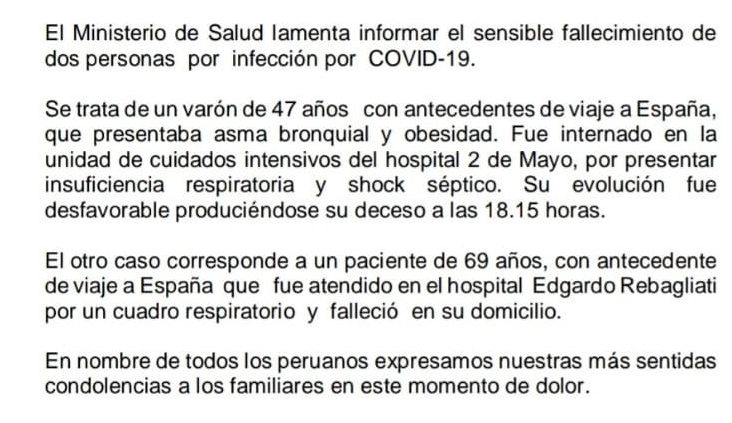

**doc_04** · impreso

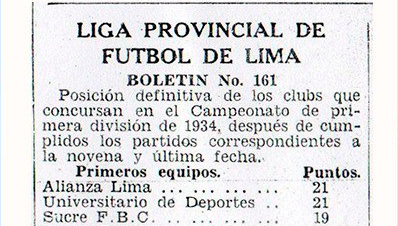

**doc_06** · impreso

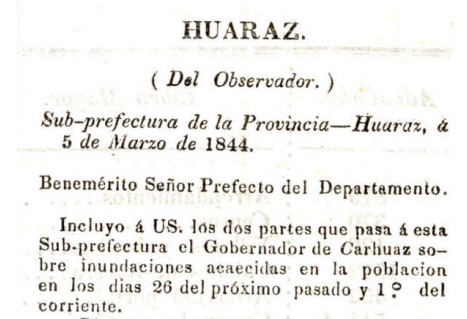

In [3]:
# los recortes publicables (sin datos personales) se muestran; los otros solo se usan en local
for f in m_docs[m_docs["publicable"]].head(3).itertuples():
    display(Markdown(f"**{f.id}** · {f.tipo}"), Image(filename=str(RAIZ / f.archivo_eval), width=520))

In [4]:
refs = pd.read_csv(DATOS / "referencias_manuales.csv")
refs = refs[refs["texto_referencia"].fillna("").str.strip() != ""].set_index("id")["texto_referencia"]
faltan = sorted(set(muestra["id"]) - set(refs.index))
assert not faltan, f"Faltan referencias manuales para: {faltan}. Usa herramientas/anotar_referencias.py"
m_docs["referencia"] = m_docs["id"].map(refs)
m_aud["referencia"] = m_aud["id"].map(refs)
print("Referencias manuales completas: 10 documentos y 10 clips")
print(f"Caracteres de referencia (documentos): {m_docs['referencia'].map(lambda t: len(t2.normalizar(t))).sum():,}")
print(f"Palabras de referencia (audio): {m_aud['referencia'].map(lambda t: len(t2.normalizar(t).split())).sum():,}")

# se guardan en los CSV del corpus (seudonimizadas, como el resto del texto publicado)
seudonimos = json.loads((DATOS / "raw" / "seudonimos.json").read_text(encoding="utf-8")) if (DATOS / "raw" / "seudonimos.json").exists() else {}
publica = {i: t2.seudonimizar(t, seudonimos)[0] for i, t in refs.items()}
documentos["texto_referencia"] = documentos["id"].map(publica).fillna("")
transcripciones["texto_referencia"] = transcripciones["id"].map(publica).fillna("")
documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)

Referencias manuales completas: 10 documentos y 10 clips
Caracteres de referencia (documentos): 3,741
Palabras de referencia (audio): 803


## 2. Configuraciones (fijadas antes de medir)

| Modalidad | Rol | Modelo y configuración |
|---|---|---|
| Documentos | **Base** | PaddleOCR 3.7, PP-OCRv6 medium, `lang="es"`, preproceso por defecto, PyTorch en GPU (igual que la Parte 1) |
| Documentos | Alternativo | EasyOCR 1.7.2, `['es']`, GPU (detector CRAFT + reconocedor CRNN, otra familia de modelos) |
| Audio | **Base** | faster-whisper `small`, int8, CPU, VAD on, `beam_size=5`, `language="es"` |
| Audio | Alternativo 1 | Qwen3-ASR 0.6B (transformers, GPU, bf16), VAD de `voz.py`, `language="es"` |
| Audio | Alternativo 2 | Whisper large-v3-turbo en faster-whisper (int8, CPU, VAD on, `beam_size=5`) |

La latencia se mide en la misma laptop (Ryzen/Intel de 16 hilos + RTX 5050 de 8 GB): segundos de proceso y
**factor de tiempo real (RTF)** = tiempo de proceso / duración del audio, indicando si corrió en CPU o GPU.
Whisper turbo corre en CPU igual que la base, para que su latencia sea comparable. Para el OCR se reportan segundos por recorte.

In [5]:
CONFIGS = {
    "PaddleOCR (base)": dict(lang="es", engine="transformers", device="gpu"),
    "EasyOCR": dict(lang_list=["es"], gpu=True),
    "faster-whisper small (base)": dict(modelo="small", language="es", beam_size=5, vad_filter=True),
    "Qwen3-ASR 0.6B": dict(clave="qwen3-asr-0.6b", device="cuda", idioma="es"),
    "Whisper large-v3-turbo": dict(modelo="mobiuslabsgmbh/faster-whisper-large-v3-turbo", language="es", beam_size=5, vad_filter=True),
}
json.dumps(CONFIGS, ensure_ascii=False, indent=1)[:800]

'{\n "PaddleOCR (base)": {\n  "lang": "es",\n  "engine": "transformers",\n  "device": "gpu"\n },\n "EasyOCR": {\n  "lang_list": [\n   "es"\n  ],\n  "gpu": true\n },\n "faster-whisper small (base)": {\n  "modelo": "small",\n  "language": "es",\n  "beam_size": 5,\n  "vad_filter": true\n },\n "Qwen3-ASR 0.6B": {\n  "clave": "qwen3-asr-0.6b",\n  "device": "cuda",\n  "idioma": "es"\n },\n "Whisper large-v3-turbo": {\n  "modelo": "mobiuslabsgmbh/faster-whisper-large-v3-turbo",\n  "language": "es",\n  "beam_size": 5,\n  "vad_filter": true\n }\n}'

## 3. Línea base sin ajuste

### 3.1 Documentos: PaddleOCR → CER

In [6]:
from paddleocr import PaddleOCR

def evaluar_ocr(nombre, leer):
    filas = []
    for f in m_docs.itertuples():
        t0 = time.perf_counter()
        texto = leer(RAIZ / f.archivo_eval)
        seg = time.perf_counter() - t0
        filas.append({"modelo": nombre, "id": f.id, "tipo": f.tipo, "hipotesis": texto, "segundos": seg,
                      "cer": t2.cer(f.referencia, texto)})
    return pd.DataFrame(filas)

paddle = PaddleOCR(**CONFIGS["PaddleOCR (base)"])
paddle.predict(str(RAIZ / m_docs["archivo_eval"].iloc[0]))   # calentamiento: no se cronometra
res_ocr = evaluar_ocr("PaddleOCR (base)", lambda r: t2.leer_paddle(paddle, r)["texto"])
cer_base = t2.cer_corpus(m_docs["referencia"], res_ocr["hipotesis"])
print(f"CER base (PaddleOCR), agregado sobre los 10 recortes: {cer_base:.3f}")
res_ocr[["id", "tipo", "cer", "segundos"]].round(3)

Creating model: ('PP-LCNet_x1_0_doc_ori', None, 'transformers')


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\USER\.paddlex\official_models\PP-LCNet_x1_0_doc_ori_safetensors`.


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 146/146 [00:00<00:00, 6484.27it/s]

Creating model: ('UVDoc', None, 'transformers')


...

Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\USER\.paddlex\official_models\PP-OCRv6_medium_rec_safetensors`.


Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 269/269 [00:00<00:00, 6162.27it/s]

CER base (PaddleOCR), agregado sobre los 10 recortes: 0.402


,id,tipo,cer,segundos
0,doc_02,impreso,0.464,0.364
1,doc_04,impreso,0.003,0.486
2,doc_06,impreso,0.036,0.278
3,doc_09,foto,0.008,0.459
4,doc_12,foto,0.348,0.337
5,doc_15,foto,0.101,0.161
6,doc_17,manuscrito,1.000,0.149
7,doc_20,manuscrito,0.200,0.324
8,doc_21,manuscrito,0.539,0.334
9,doc_24,manuscrito,0.232,0.282


### 3.2 Audio: faster-whisper `small` en CPU → WER y latencia

En la evaluación se transcribe el clip sin diarización (las marcas de hablante no son palabras habladas); el WER se
calcula con `t2.normalizar`, que además elimina cualquier marca `[HABLANTE_n]`.

In [7]:
from faster_whisper import WhisperModel

audios = {f.id: sf.read(RAIZ / f.archivo_eval, dtype="float32")[0] for f in m_aud.itertuples()}

def evaluar_asr(nombre, transcribir):
    filas = []
    for f in m_aud.itertuples():
        x = audios[f.id]
        t0 = time.perf_counter()
        texto = transcribir(x)
        seg = time.perf_counter() - t0
        filas.append({"modelo": nombre, "id": f.id, "condicion": f.tipo, "hipotesis": texto, "segundos": seg,
                      "duracion": len(x) / voz.SR, "wer": t2.wer(f.referencia, texto)})
    df = pd.DataFrame(filas)
    df["rtf"] = df["segundos"] / df["duracion"]
    return df

def whisper_fw(cfg):
    m = WhisperModel(cfg["modelo"], device="cpu", compute_type="int8", cpu_threads=8)
    kw = {k: v for k, v in cfg.items() if k != "modelo"}
    m.transcribe(np.zeros(voz.SR, dtype=np.float32), language="es")      # calentamiento
    return lambda x: " ".join(s.text.strip() for s in m.transcribe(x, **kw)[0])

res_asr = evaluar_asr("faster-whisper small (base)", whisper_fw(CONFIGS["faster-whisper small (base)"]))
wer_base = t2.wer_corpus(m_aud["referencia"], res_asr["hipotesis"])
print(f"WER base (faster-whisper small, CPU), agregado sobre los 10 clips: {wer_base:.3f} · "
      f"RTF mediano {res_asr['rtf'].median():.2f}")
res_asr[["id", "condicion", "wer", "segundos", "rtf"]].round(3)

WER base (faster-whisper small, CPU), agregado sobre los 10 clips: 0.258 · RTF mediano 0.23


,id,condicion,wer,segundos,rtf
0,clip_53,lectura en estudio (OpenSLR 73),0.000,2.190,0.395
1,clip_54,lectura en estudio (OpenSLR 73),0.000,1.500,0.172
2,clip_57,lectura en estudio (OpenSLR 73),0.077,1.515,0.228
3,clip_58,lectura en estudio (OpenSLR 73),0.111,1.829,0.228
4,clip_22,calle con multitud y bocinas,0.474,5.120,0.171
5,clip_04,"calle, entrevista multihablante",0.287,15.498,0.254
6,clip_26,feria al aire libre,0.336,14.760,0.246
7,clip_23,"plaza, entrevista breve",0.547,7.207,0.165
8,clip_11,conferencia de prensa con eco,0.126,16.558,0.264
9,clip_41,testimonio en interior,0.146,14.689,0.240


## 4. Extracción estructurada con LLM y auditoría humana

**Modelo:** Qwen2.5-3B-Instruct (Alibaba, Qwen Research License), local en la GPU de la laptop (RTX 5050), cuantizado a 4 bits
(NF4) para que quepa en 8 GB de VRAM, con decodificación greedy. Corre en un entorno aparte (`.venv-gpu`, PyTorch con CUDA) con `herramientas/extraer_llm.py`.

**Prompt:** un mensaje de sistema con reglas estrictas (solo JSON, `null` si el dato no aparece, no corregir ni
inventar, copiar seudónimos tal cual) y un esquema distinto por modalidad:

- Documentos: `modalidad`, `tipo_documento`, `tema`, `resumen`, `emisor`, `fecha`, `lugar`, `monto`.
- Audios: `modalidad`, `tipo_audio`, `tema`, `resumen`, `citas_clave`, `numero_hablantes` (solo si hay marcas
  `[HABLANTE_n]`), `lugar`.

Se procesan los textos **seudonimizados** de todo el corpus (25 documentos y todos los clips).

In [8]:
EXT = DATOS / "extraccion_llm.csv"
if not EXT.exists():
    py_llm = RAIZ / ".venv-gpu" / "Scripts" / "python.exe"
    r = subprocess.run([str(py_llm), str(RAIZ / "herramientas" / "extraer_llm.py")], capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-3000:], r.stderr[-1500:])
ext = pd.read_csv(EXT)
ext["campos"] = ext["campos_json"].map(json.loads)
print(f"{len(ext)} extracciones · JSON válido: {ext['json_valido'].mean():.0%} · "
      f"mediana de {ext['segundos'].median():.1f} s por texto en GPU · modelo: {ext['modelo_llm'].iloc[0]}")
ext[["id", "modalidad", "campos_json", "modelo_llm", "fecha"]].head(6)

83 extracciones · JSON válido: 99% · mediana de 16.1 s por texto en GPU · modelo: Qwen/Qwen2.5-3B-Instruct (4-bit NF4, GPU, greedy)


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_01,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""comunicado"", ""tema"": ""fallecim...","Qwen/Qwen2.5-3B-Instruct (4-bit NF4, GPU, greedy)",2026-10-26
1,doc_02,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""comunicado"", ""tema"": ""Sensible...","Qwen/Qwen2.5-3B-Instruct (4-bit NF4, GPU, greedy)",2026-10-26
2,doc_03,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""carta"", ""tema"": ""envío de retr...","Qwen/Qwen2.5-3B-Instruct (4-bit NF4, GPU, greedy)",2026-10-26
3,doc_04,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""boletín"", ""tema"": ""posición fi...","Qwen/Qwen2.5-3B-Instruct (4-bit NF4, GPU, greedy)",2026-10-26
4,doc_05,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""otro"", ""tema"": ""Relaciones int...","Qwen/Qwen2.5-3B-Instruct (4-bit NF4, GPU, greedy)",2026-10-26
5,doc_06,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""otro"", ""tema"": ""Inundaciones e...","Qwen/Qwen2.5-3B-Instruct (4-bit NF4, GPU, greedy)",2026-10-26


In [9]:
# cobertura de campos: cuántas veces el LLM llenó cada campo y cuántas puso null
cob = []
for mod, g in ext.groupby("modalidad"):
    campos = pd.DataFrame(list(g["campos"]))
    for c in campos.columns.drop(["modalidad"], errors="ignore"):
        if c in ("error", "respuesta_cruda"):
            continue
        cob.append({"modalidad": mod, "campo": c, "con_valor": campos[c].map(lambda v: v not in (None, "", [], "null")).mean()})
pd.DataFrame(cob).pivot(index="campo", columns="modalidad", values="con_valor").round(2)

modalidad,audio,documento
campo,,
citas_clave,0.98,NaN
emisor,NaN,0.84
fecha,NaN,1.00
lugar,0.90,1.00
monto,NaN,0.84
numero_hablantes,0.66,NaN
resumen,1.00,1.00
tema,0.98,1.00
tipo_audio,1.00,NaN


### 4.1 Auditoría humana de 20 extracciones al azar

Muestra: 10 documentos y 10 audios elegidos con semilla fija (`preparar_muestra.muestra_auditoria`, semilla 2026),
revisados uno por uno con `herramientas/auditar_llm.py` frente al texto fuente.

**Criterios de corrección por campo:** correcto si el valor está en el texto (o es `null` y el dato no aparece);
incorrecto si es inventado o deducido, contradice el texto o es `null` cuando el dato aparece claramente.
`tema` y `resumen` deben ser fieles al texto; `citas_clave` deben ser frases copiadas del texto.
Una extracción es **completamente correcta** si todos sus campos lo son.

In [10]:
aud = pd.read_csv(DATOS / "auditoria_llm.csv")
muestra_aud = pd.read_csv(DATOS / "muestra_auditoria.csv")
assert set(aud["id"]) == set(muestra_aud["id"]) and len(aud) == 20, "La auditoría debe cubrir las 20 extracciones de la muestra"
correctas = int(aud["completamente_correcta"].sum())
print(f"Acuerdo LLM-Humano: {correctas}/20 extracciones completamente correctas ({correctas / 20:.0%})")
print(aud.groupby("modalidad")["completamente_correcta"].agg(["sum", "count"]).rename(columns={"sum": "correctas", "count": "auditadas"}).to_string())
campos_ok = aud.filter(like="ok_").mean().rename(lambda c: c[3:]).sort_values()
display(campos_ok.round(2).rename("proporción de campos correctos").to_frame())

Acuerdo LLM-Humano: 13/20 extracciones completamente correctas (65%)
           correctas  auditadas
modalidad                      
audio              7         10
documento          6         10


,proporción de campos correctos
emisor,0.8
tipo_audio,0.8
numero_hablantes,0.8
resumen,0.85
tema,0.9
lugar,0.9
tipo_documento,1.0
fecha,1.0
monto,1.0
citas_clave,1.0


In [11]:
# qué campos marcó como incorrectos la auditoría, junto al valor que había puesto el LLM
fallos = []
for r in aud[~aud["completamente_correcta"].astype(bool)].itertuples():
    campos = ext.set_index("id").loc[r.id, "campos"]
    malos = [c[3:] for c in aud.filter(like="ok_").columns if getattr(r, c) is False or getattr(r, c) == "False"]
    fallos.append({"id": r.id, "modalidad": r.modalidad, "campos incorrectos": ", ".join(malos),
                   "valor del LLM": " | ".join(f"{c}: {json.dumps(campos.get(c), ensure_ascii=False)[:90]}" for c in malos),
                   "nota del auditor": r.errores if isinstance(r.errores, str) else ""})
display(Markdown("**Ejemplos de errores encontrados en la auditoría**"))
pd.DataFrame(fallos)

**Ejemplos de errores encontrados en la auditoría**

,id,modalidad,campos incorrectos,valor del LLM,nota del auditor
0,doc_16,documento,"resumen, lugar","resumen: ""El documento es una carta sobre la reunión del bicentenario."" | lu...",En la primera frase toda la oración esta junta
1,doc_19,documento,"emisor, lugar","emisor: ""Gilles Porras"" | lugar: ""San Blas, Puebla, México""",
2,doc_17,documento,emisor,"emisor: ""M Consiá Regadélhing""",
3,doc_18,documento,"tema, resumen","tema: ""carta de presentación"" | resumen: ""... carta de presentación""",
4,clip_12,audio,tipo_audio,"tipo_audio: ""conferencia""",
5,clip_19,audio,"tema, resumen, numero_hablantes","tema: ""tema principal en pocas palabras"" | resumen: ""..."" | numero_hablantes...",
6,clip_24,audio,"tipo_audio, numero_hablantes","tipo_audio: ""conferencia"" | numero_hablantes: ""null""",


## 5. Mejora y comparación de modelos (mismas muestras)

### 5.1 Documentos: EasyOCR

In [12]:
import easyocr
lector = easyocr.Reader(**CONFIGS["EasyOCR"], verbose=False)
lector.readtext(str(RAIZ / m_docs["archivo_eval"].iloc[0]))         # calentamiento
res_ocr = pd.concat([res_ocr, evaluar_ocr("EasyOCR", lambda r: t2.leer_easyocr(lector, r)["texto"])], ignore_index=True)
cer_por_modelo = res_ocr.groupby("modelo").apply(lambda g: t2.cer_corpus(m_docs.set_index("id").loc[g["id"], "referencia"], g["hipotesis"]))
print(cer_por_modelo.round(3).to_string())

modelo
EasyOCR             0.355
PaddleOCR (base)    0.402


### 5.2 Audio: Qwen3-ASR 0.6B y Whisper large-v3-turbo

In [13]:
qwen = voz.Transcriptor(CONFIGS["Qwen3-ASR 0.6B"]["clave"], device="cuda")
qwen.transcribir(np.zeros(voz.SR, dtype=np.float32), "es")          # calentamiento
res_asr = pd.concat([res_asr,
                     evaluar_asr("Qwen3-ASR 0.6B", lambda x: " ".join(s.texto for s in qwen.segmentos(x, idioma="es"))),
                     evaluar_asr("Whisper large-v3-turbo", whisper_fw(CONFIGS["Whisper large-v3-turbo"]))], ignore_index=True)
ref_aud = m_aud.set_index("id")["referencia"]
wer_por_modelo = res_asr.groupby("modelo").apply(lambda g: t2.wer_corpus(ref_aud.loc[g["id"]], g["hipotesis"]))
# RTF = mediana por clip: una pausa del equipo (clip_26 con Qwen3-ASR tardó ~15 min) no debe definir la latencia
rtf_por_modelo = res_asr.groupby("modelo")["rtf"].median()
print("Clips con tiempo anómalo (> 5 veces la mediana de su modelo):")
print(res_asr[res_asr["rtf"] > 5 * res_asr["modelo"].map(rtf_por_modelo)][["modelo", "id", "segundos", "rtf"]].round(2).to_string())
DISPOSITIVO = {"faster-whisper small (base)": "CPU", "Qwen3-ASR 0.6B": "GPU", "Whisper large-v3-turbo": "CPU"}
pd.DataFrame({"WER": wer_por_modelo, "RTF": rtf_por_modelo, "dispositivo": pd.Series(DISPOSITIVO)}).round(3)

Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

Loading weights:  71%|███████   | 431/611 [00:00<00:00, 4105.01it/s]

Loading weights: 100%|██████████| 611/611 [00:00<00:00, 4146.57it/s]

Clips con tiempo anómalo (> 5 veces la mediana de su modelo):
Empty DataFrame
Columns: [modelo, id, segundos, rtf]
Index: []


,WER,RTF,dispositivo
Qwen3-ASR 0.6B,0.250,0.356,GPU
Whisper large-v3-turbo,0.244,0.476,CPU
faster-whisper small (base),0.258,0.234,CPU


In [14]:
# un ejemplo lado a lado: el clip con más diferencia de WER entre modelos
piv = res_asr.pivot(index="id", columns="modelo", values="wer")
ej = (piv.max(axis=1) - piv.min(axis=1)).idxmax()
display(Markdown(f"**{ej}** ({m_aud.set_index('id').loc[ej, 'tipo']})"))
display(Markdown("> Referencia: " + t2.seudonimizar(ref_aud[ej], seudonimos)[0][:400]))
for r in res_asr[res_asr["id"] == ej].itertuples():
    display(Markdown(f"> **{r.modelo}** (WER {r.wer:.2f}): {t2.seudonimizar(r.hipotesis, seudonimos)[0][:400]}"))

**clip_22** (calle con multitud y bocinas)

> Referencia: Normal pe esperando resultados nomas ¿no? 
Pero cómo lo ves, cómo ves a Perú ahorita que esta
Que cómo veo a Perú, Perú la veo y bájalas taaa no se no se entiende pe, no se estan entendiendo, no no. Hay como cuatro jugadores que están por las puras y ya pe y ahora el técnico tiene que hacer justo los cambios ¿no? Supongo de esos cuatro jugadores: Carrillo, Canchita, este Trauco y ala el otro si no

> **faster-whisper small (base)** (WER 0.47): Normal, pero no lo esperamos Pero como lo ves? Como ves a Perú ahorita? Como ves a Perú No se entiende No se están entendiendo Hay como 4 jugadores que están por las puras Y ahora El técnico tiene que hacer Justo los cambios Supongo esos 4 jugadores Carrillo, Canchita Trauco Y ahora lo haces

> **Qwen3-ASR 0.6B** (WER 0.32): normal prefiero no resaltar más pero cómo lo ves cómo ves a Perú ahorita que está cómo lo ves Perú Perú lo ves hasta las está no se no se entiende ven no se están entendiendo no no hay como cuatro jugadores que están por las puras y ya ve ahora el técnico tiene que hacer justo los cambios supongo esos cuatro jugadores carrillo canchita este trauco y y a la lota sino

> **Whisper large-v3-turbo** (WER 0.45): normal esperando resultados pero como lo ves como ves a perú ahorita que está no se entiende no se están entendiendo hay como cuatro jugadores que están por las puras y ahora el técnico tiene que hacer justo los cambios pero supongo esos cuatro jugadores que es carrillo canchita este trauco y y ahora lo que sí no

## 6. Casos difíciles

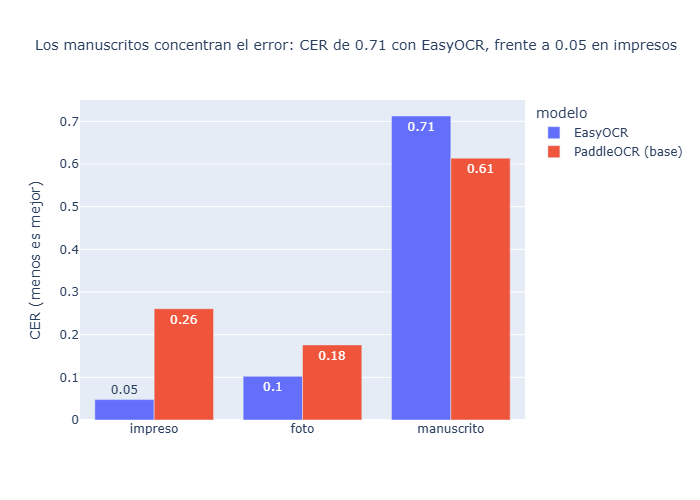

modelo,EasyOCR,PaddleOCR (base)
tipo,,
foto,0.102,0.176
impreso,0.048,0.261
manuscrito,0.713,0.614


In [15]:
por_tipo = res_ocr.groupby(["modelo", "tipo"]).apply(
    lambda g: t2.cer_corpus(m_docs.set_index("id").loc[g["id"], "referencia"], g["hipotesis"])).rename("CER").reset_index()
peor = por_tipo.loc[por_tipo["CER"].idxmax()]
fig = px.bar(por_tipo, x="tipo", y="CER", color="modelo", barmode="group", text=por_tipo["CER"].round(2),
             category_orders={"tipo": ["impreso", "foto", "manuscrito"]},
             title=f"Los manuscritos concentran el error: CER de {peor['CER']:.2f} con {peor['modelo']}, frente a "
                   f"{por_tipo[por_tipo['tipo'] == 'impreso']['CER'].min():.2f} en impresos")
fig.update_layout(title_font_size=14, yaxis_title="CER (menos es mejor)", xaxis_title="")
fig.show()
por_tipo.pivot(index="tipo", columns="modelo", values="CER").round(3)

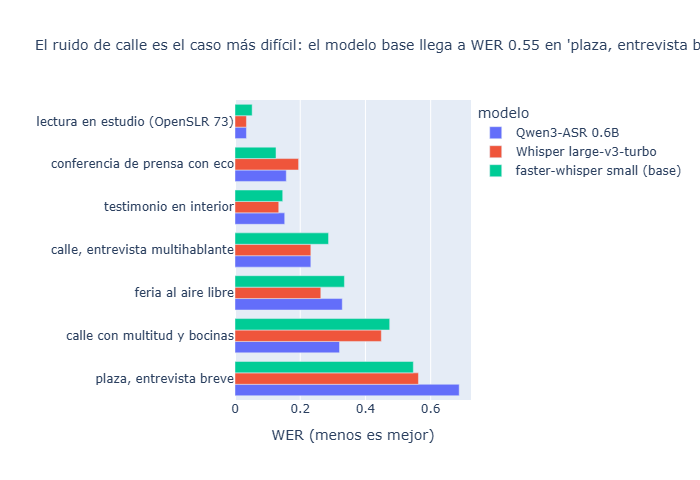

modelo,Qwen3-ASR 0.6B,Whisper large-v3-turbo,faster-whisper small (base)
condicion,,,
calle con multitud y bocinas,0.321,0.449,0.474
"calle, entrevista multihablante",0.233,0.233,0.287
conferencia de prensa con eco,0.157,0.195,0.126
feria al aire libre,0.329,0.263,0.336
lectura en estudio (OpenSLR 73),0.035,0.035,0.053
"plaza, entrevista breve",0.688,0.562,0.547
testimonio en interior,0.152,0.134,0.146


In [16]:
por_cond = res_asr.groupby(["modelo", "condicion"]).apply(
    lambda g: t2.wer_corpus(ref_aud.loc[g["id"]], g["hipotesis"])).rename("WER").reset_index()
orden = por_cond[por_cond["modelo"].str.contains("base")].sort_values("WER")["condicion"].tolist()
peor = por_cond[por_cond["modelo"].str.contains("base")].iloc[por_cond[por_cond["modelo"].str.contains("base")]["WER"].argmax()]
fig = px.bar(por_cond, x="WER", y="condicion", color="modelo", barmode="group", orientation="h",
             category_orders={"condicion": orden},
             title=f"El ruido de calle es el caso más difícil: el modelo base llega a WER {peor['WER']:.2f} en '{peor['condicion']}'")
fig.update_layout(title_font_size=14, xaxis_title="WER (menos es mejor)", yaxis_title="", height=480)
fig.show()
por_cond.pivot(index="condicion", columns="modelo", values="WER").round(3)

## 7. Tabla comparativa y decisión

In [17]:
seg_ocr = res_ocr.groupby("modelo")["segundos"].mean()
tabla = pd.concat([
    pd.DataFrame({"modalidad": "documentos", "métrica": "CER", "valor": cer_por_modelo,
                  "latencia": seg_ocr.map(lambda s: f"{s:.2f} s por recorte (GPU)"),
                  "CER/WER peor caso": por_tipo.groupby("modelo")["CER"].max()}),
    pd.DataFrame({"modalidad": "audio", "métrica": "WER", "valor": wer_por_modelo,
                  "latencia": [f"RTF {r:.2f} ({DISPOSITIVO[m]})" for m, r in rtf_por_modelo.items()],
                  "CER/WER peor caso": por_cond.groupby("modelo")["WER"].max()}),
]).rename_axis("modelo").reset_index()
tabla["rol"] = np.where(tabla["modelo"].str.contains("base"), "base", "alternativo")
tabla = tabla[["modalidad", "modelo", "rol", "métrica", "valor", "CER/WER peor caso", "latencia"]]
tabla.round(3)

,modalidad,modelo,rol,métrica,valor,CER/WER peor caso,latencia
0,documentos,EasyOCR,alternativo,CER,0.355,0.713,0.52 s por recorte (GPU)
1,documentos,PaddleOCR (base),base,CER,0.402,0.614,0.32 s por recorte (GPU)
2,audio,Qwen3-ASR 0.6B,alternativo,WER,0.250,0.688,RTF 0.36 (GPU)
3,audio,Whisper large-v3-turbo,alternativo,WER,0.244,0.562,RTF 0.48 (CPU)
4,audio,faster-whisper small (base),base,WER,0.258,0.547,RTF 0.23 (CPU)


In [18]:
# resultados que se guardan para el dashboard
tabla.to_csv(DATOS / "metricas_modelos.csv", index=False)
detalle = pd.concat([res_ocr.rename(columns={"cer": "error"}).assign(metrica="CER", modalidad="documento", condicion=lambda d: d["tipo"]),
                     res_asr.rename(columns={"wer": "error"}).assign(metrica="WER", modalidad="audio")])[
    ["modalidad", "modelo", "id", "condicion", "metrica", "error", "segundos", "hipotesis"]]
# lo que se publica va seudonimizado, igual que el resto del corpus (las métricas ya se calcularon con el texto original)
detalle["hipotesis"] = [t2.seudonimizar(str(t), seudonimos)[0] for t in detalle["hipotesis"]]
detalle.to_csv(DATOS / "metricas_detalle.csv", index=False)

mejor_ocr, mejor_asr = cer_por_modelo.idxmin(), wer_por_modelo.idxmin()
print(f"Mejor OCR en la muestra: {mejor_ocr} (CER {cer_por_modelo.min():.3f})")
print(f"Mejor ASR en la muestra: {mejor_asr} (WER {wer_por_modelo.min():.3f}, RTF {rtf_por_modelo[mejor_asr]:.2f})")

Mejor OCR en la muestra: EasyOCR (CER 0.355)
Mejor ASR en la muestra: Whisper large-v3-turbo (WER 0.244, RTF 0.48)


### Decisión

**Documentos → EasyOCR.** En los mismos 10 recortes tiene menor CER agregado que PaddleOCR (0,355 frente a 0,402) y es
claramente mejor en impresos (0,05 frente a 0,26) y fotos (0,10 frente a 0,18). Los dos corren en menos de 1 s por recorte
en GPU, así que el costo no decide. Matiz importante: gran parte de la desventaja de PaddleOCR viene de un solo recorte
(`doc_02`, un comunicado impreso y limpio, CER 0,46): el "planchado" de página por defecto (UVDoc) deformó la mitad superior
de una imagen que ya era plana. No probamos desactivarlo porque sería ajustar la configuración después de ver las
métricas; queda como el siguiente experimento, con otra muestra. En manuscritos ninguno sirve (CER 0,61–0,71).

**Audio → faster-whisper `small`.** Los tres modelos quedan prácticamente empatados: WER 0,258 (`small`), 0,250
(Qwen3-ASR 0.6B) y 0,244 (Whisper large-v3-turbo). La diferencia entre el mejor y la base son unas 11 palabras de 803,
dentro de lo que puede variar con solo 10 clips. Con ese empate manda el costo: `small` corre en CPU a la mitad del tiempo
que turbo (RTF ~0,25 frente a ~0,5 en esta laptop) y no necesita GPU (Qwen3-ASR queda en ~0,3, pero solo en GPU), que en un archivo real (una biblioteca, un despacho, una ONG) suele
no haber. Para un lote grande de audios de calle cambiaríamos a Qwen3-ASR, que fue el más robusto con multitudes (ver abajo).

### Reflexión por tipo de documento y de audio

- **Impresos: el mejor caso.** Con EasyOCR el CER es 0,05; el boletín de 1934 (`doc_04`) y la columna de *El Peruano* de 1844
  (`doc_06`) salen casi perfectos incluso con tipografía y ortografía antiguas. El error grande fue de preprocesamiento, no de lectura.
- **Fotos: depende más del tamaño de letra que de la sombra.** El aviso de *Época* (`doc_09`), con luz tenue pero letra grande,
  tiene CER 0,01; la resolución fotografiada inclinada y con letra pequeña (`doc_12`) llega a 0,35 con PaddleOCR.
- **Manuscritos: el peor caso, por lejos.** En el Acta de la Independencia (`doc_17`, cursiva de 1821) PaddleOCR no detecta ni
  una línea (CER 1,0) y EasyOCR devuelve basura. El diploma caligráfico de 1921 (`doc_20`) y el recibo de 1895 (`doc_24`) salen
  mejor (0,20–0,23) porque mezclan texto impreso con letra cuidada. Estos modelos se entrenaron con texto impreso o de escena;
  para manuscritos hace falta un modelo de reconocimiento de escritura a mano (TrOCR, PaddleOCR-VL) o transcripción humana.
- **Audio leído en estudio: casi perfecto** (WER ≤ 0,05 en OpenSLR 73).
- **Audio en la calle: el peor caso.** La entrevista breve en la plaza (`clip_23`, siete voces en 44 s, frases cortadas) llega a
  WER 0,55–0,69 con todos los modelos, y la calle con multitud y bocinas (`clip_22`) a 0,47 con `small`. Aquí Qwen3-ASR bajó a 0,32:
  es el único caso donde el modelo cambia el resultado de verdad. El VAD evitó texto inventado en silencios, pero no puede
  separar voces superpuestas.
- **Conferencia con eco y testimonio en interior: buen nivel** (WER 0,13–0,20): una sola voz principal, cerca del micrófono.
- **LLM (13/20 completamente correctas).** Los errores siguen al texto de entrada: con OCR basura de manuscritos el LLM inventa
  emisores y lugares (`doc_19`: "San Blas, Puebla, México"; `doc_17`: un emisor ilegible), confunde entrevistas con conferencias
  (`clip_12`, `clip_24`) y en un clip copió literalmente el texto de ejemplo del esquema ("tema principal en pocas palabras",
  `clip_19`). Las fechas y montos, en cambio, salieron siempre bien: el modelo respeta el `null` cuando el dato no está.

In [19]:
ELEGIDO_OCR = "EasyOCR"                          # ver la decisión
ELEGIDO_ASR = "faster-whisper small (base)"
print("Resultados Test: "
      f"WER: {wer_por_modelo[ELEGIDO_ASR]:.2f} | CER: {cer_por_modelo[ELEGIDO_OCR]:.2f} | Acuerdo LLM-Humano: {correctas}/20")

Resultados Test: WER: 0.26 | CER: 0.36 | Acuerdo LLM-Humano: 13/20
